# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        X_ext = np.hstack([np.ones((X.shape[0], 1)), X])
        if self.w0 is None:
            self.w = np.zeros(X_ext.shape[1], dtype=float)
        else:
            self.w = np.asarray(self.w0, dtype=float).copy()

        for _ in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X_ext, y))
            if self.gd_type == 'full':
                grad = self.calc_gradient(X_ext, y)
            elif self.gd_type == 'stochastic':
                idx = rng.choice(X_ext.shape[0], size=min(self.batch_size, X_ext.shape[0]), replace=False)
                grad = self.calc_gradient(X_ext[idx], y[idx])
            else:
                raise ValueError('Invalid gd_type')

            w_new = self.w - self.eta * grad
            if np.linalg.norm(w_new - self.w) < self.tolerance:
                self.w = w_new
                break
            self.w = w_new

        return self

    def sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -250, 250)))

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        X = np.asarray(X, dtype=float)
        X_ext = np.hstack([np.ones((X.shape[0], 1)), X])
        p1 = self.sigmoid(X_ext @ self.w)
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        p = self.sigmoid(X @ self.w)
        return (X.T @ (p - y)) / len(y)

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        p = np.clip(self.sigmoid(X @ self.w), 1e-15, 1.0 - 1e-15)
        return float(-np.mean(y * np.log(p) + (1.0 - y) * np.log(1.0 - p)))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 2.28e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

Full GD iterations: 1000
Stochastic GD iterations: 1000


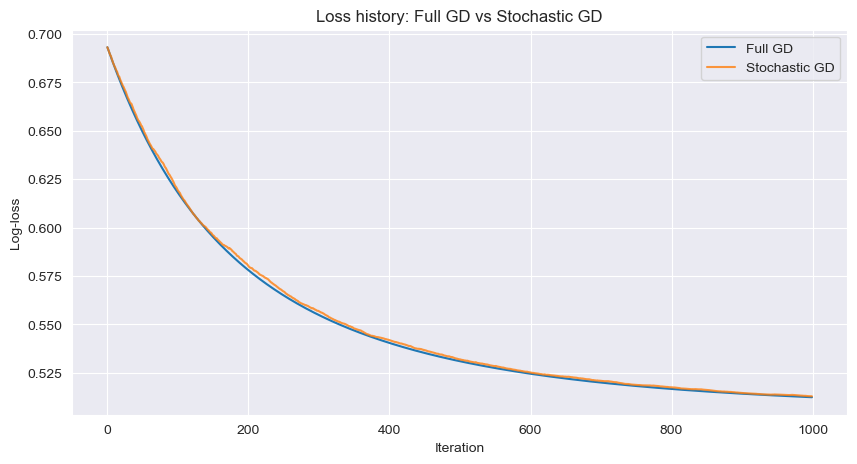

In [6]:
model_gd = LogReg(gd_type='full').fit(X_train, y_train)
model_sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)

print(f'Full GD iterations: {len(model_gd.loss_history)}')
print(f'Stochastic GD iterations: {len(model_sgd.loss_history)}')

plt.figure(figsize=(10, 5))
plt.plot(model_gd.loss_history, label='Full GD')
plt.plot(model_sgd.loss_history, label='Stochastic GD', alpha=0.8)
plt.xlabel('Iteration')
plt.ylabel('Log-loss')
plt.title('Loss history: Full GD vs Stochastic GD')
plt.legend()
plt.show()

Обе модели выполнили по 1000 итераций и остановились по `max_iter`: критерий `tolerance` не был достигнут. При постоянном шаге случайный состав батча создаёт шум в градиенте, поэтому стохастическому спуску трудно получить устойчиво малое изменение весов даже около минимума.

У полного GD функция потерь убывает плавно, у стохастического возможны небольшие колебания. Для вычисления градиента полный GD использует все 14000 тренировочных объектов, стохастический — 32. При этом в данной реализации оба метода дополнительно вычисляют loss на всей тренировочной выборке на каждой итерации, поэтому полная стоимость итерации SGD не ограничивается обработкой 32 объектов.


### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

eta=0.001: iterations = 1000, final loss = 0.6181
eta=0.01: iterations = 1000, final loss = 0.5124
eta=0.1: iterations = 465, final loss = 0.5058
eta=1: iterations = 70, final loss = 0.5058
eta=10: iterations = 1000, final loss = 0.9013


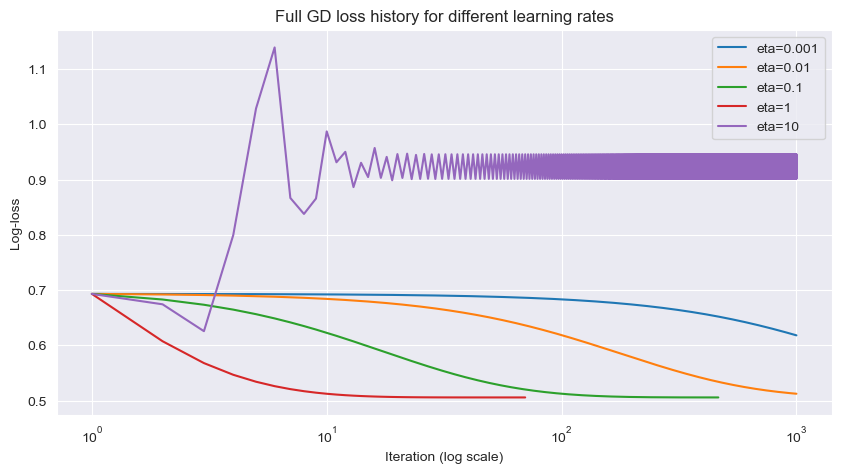

In [7]:
etas = [1e-3, 1e-2, 1e-1, 1, 10]
plt.figure(figsize=(10, 5))
X_train_ext = np.column_stack([np.ones(len(X_train)), X_train])

for eta in etas:
    model = LogReg(gd_type='full', eta=eta).fit(X_train, y_train)
    final_loss = model.calc_loss(X_train_ext, y_train)
    print(f'eta={eta}: iterations = {len(model.loss_history)}, final loss = {final_loss:.4f}')
    plt.plot(range(1, len(model.loss_history) + 1), model.loss_history, label=f'eta={eta}')

plt.xscale('log')
plt.xlabel('Iteration (log scale)')
plt.ylabel('Log-loss')
plt.title('Full GD loss history for different learning rates')
plt.legend()
plt.show()

При `eta=0.001` спуск идёт медленно: после 1000 итераций loss составляет около 0.6181. При `eta=0.01` за те же 1000 итераций он уменьшается до 0.5124, но критерий `tolerance` также не достигается.

При `eta=0.1` остановка по `tolerance` происходит за 465 итераций, при `eta=1` — за 70; в обоих случаях loss близок к 0.5058. Среди проверенных значений `eta=1` обеспечивает наиболее быструю сходимость. При `eta=10` шаг слишком велик: loss колеблется, модель достигает лимита 1000 итераций с финальной потерей около 0.9013. Увеличение шага ускоряет сходимость лишь до некоторого предела.


### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
model_sk = LogisticRegression(random_state=RANDOM_STATE).fit(X_train, y_train)

models_1_4 = {
    'LogReg (GD)': model_gd,
    'LogReg (SGD)': model_sgd,
    'sklearn LogisticRegression': model_sk
}

results_1_4 = []
for name, m in models_1_4.items():
    y_pred = m.predict(X_test)
    y_prob = m.predict_proba(X_test)[:, 1]
    results_1_4.append({
        'Model': name,
        'Accuracy': metrics.accuracy_score(y_test, y_pred),
        'ROC-AUC': metrics.roc_auc_score(y_test, y_prob)
    })

df_results_1_4 = pd.DataFrame(results_1_4).set_index('Model')
display(df_results_1_4)

sk_w = np.hstack([model_sk.intercept_, model_sk.coef_.ravel()])
weights_df = pd.DataFrame({
    'LogReg (GD)': model_gd.w,
    'sklearn': sk_w,
    'Abs diff': np.abs(model_gd.w - sk_w)
})
display(weights_df)

,Accuracy,ROC-AUC
Model,,
LogReg (GD),0.7820,0.838787
LogReg (SGD),0.7825,0.838115
sklearn LogisticRegression,0.7765,0.838676


,LogReg (GD),sklearn,Abs diff
0,-0.002114,-0.021880,0.019765
1,0.006076,0.002741,0.003335
2,0.006963,0.009039,0.002077
3,-0.547170,-0.722690,0.175520
4,-0.144536,-0.262335,0.117799
5,0.012487,0.016588,0.004102
6,-0.006325,-0.011488,0.005163
7,0.000814,0.005587,0.004773
8,0.039084,0.057188,0.018104
9,-0.002425,-0.001239,0.001185


Метрики близки, но не совпадают: accuracy составляет 0.7820 у GD, 0.7825 у SGD и 0.7765 у sklearn; ROC-AUC — примерно 0.8388, 0.8381 и 0.8387 соответственно. Веса также различаются.

`LogisticRegression` по умолчанию использует L2-регуляризацию с `C=1`, а наш класс минимизирует log-loss без штрафа. Для одинаковой задачи оптимизации регуляризацию нужно отключить: в scikit-learn 1.8 это `LogisticRegression(C=np.inf)`; в версиях, поддерживающих соответствующий параметр, используется `penalty=None`. Дополнительная причина различий — наш GD с параметрами по умолчанию не достиг `tolerance` за 1000 итераций. Даже при одинаковом функционале близость решения зависит от достаточной сходимости; при линейно зависимых признаках веса без регуляризации могут быть неединственными.


## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
print('Missing values:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print(f'Train class 1 prevalence: {y_train.mean():.4f}')
print(f'Test class 1 prevalence: {y_test.mean():.4f}')

const_pred = np.zeros_like(y_test)
const_acc = metrics.accuracy_score(y_test, const_pred)
print(f'Constant model accuracy: {const_acc:.4f}')

pipe_lr = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
pipe_lr.fit(X_train, y_train)
lr_acc = metrics.accuracy_score(y_test, pipe_lr.predict(X_test))
print(f'LogisticRegression accuracy: {lr_acc:.4f}')

Missing values: 0
Duplicate rows: 1177
Train class 1 prevalence: 0.1966
Test class 1 prevalence: 0.1964
Constant model accuracy: 0.8036
LogisticRegression accuracy: 0.8200


Пропусков нет, полных дубликатов строк — 1177. По одним признакам нельзя установить, являются ли совпадения повторным учётом одного образца или независимыми винами с одинаковыми измерениями. В первом случае повторы следует удалить или держать в одной части при разбиении, во втором автоматическое удаление необязательно. Здесь сохранено заданное разбиение для сравнения методов. Его ограничение: 537 тестовых строк полностью совпадают со строками train, поэтому при повторном учёте одних образцов оценка качества может оказаться завышенной.

Доля класса 1 равна примерно 0.1966 в train и 0.1964 в test. `stratify=y` сохраняет близкие доли классов при разбиении.

Константная модель получает accuracy 0.8036, логистическая регрессия — 0.8200. Высокая accuracy достижима даже без обнаружения хороших вин, поскольку около 80% объектов относятся к классу 0. Поэтому для задачи также нужны precision, recall, F-меры и метрики ранжирования.


### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP = 98, TN = 1501, FP = 66, FN = 285
sklearn confusion_matrix:
 [[1501   66]
 [ 285   98]]


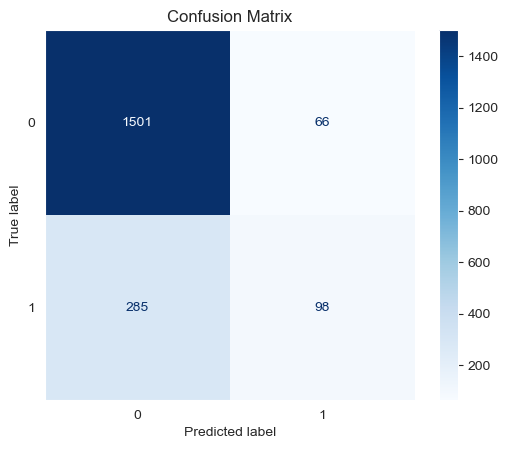

In [12]:
y_pred = pipe_lr.predict(X_test)

TP = int(np.sum((y_test == 1) & (y_pred == 1)))
TN = int(np.sum((y_test == 0) & (y_pred == 0)))
FP = int(np.sum((y_test == 0) & (y_pred == 1)))
FN = int(np.sum((y_test == 1) & (y_pred == 0)))

print(f'TP = {TP}, TN = {TN}, FP = {FP}, FN = {FN}')

cm = metrics.confusion_matrix(y_test, y_pred)
print('sklearn confusion_matrix:\n', cm)

disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.grid(False)
plt.title('Confusion Matrix')
plt.show()

Получено TP=98, TN=1501, FP=66 и FN=285. Ручной расчёт совпадает с `confusion_matrix` в порядке строк и столбцов `[0, 1]`.

FP — посредственное вино ошибочно рекомендовано как хорошее. FN — хорошее вино не попало в подборку. Чаще встречаются пропуски хороших вин: FN=285 против FP=66.


### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)

def calc_fbeta(prec, rec, beta):
    return (1 + beta**2) * prec * rec / (beta**2 * prec + rec)

f1 = calc_fbeta(precision, recall, 1.0)
f05 = calc_fbeta(precision, recall, 0.5)
f2 = calc_fbeta(precision, recall, 2.0)

df_f_metrics = pd.DataFrame({
    'Manual': [precision, recall, f1, f05, f2],
    'sklearn': [
        metrics.precision_score(y_test, y_pred),
        metrics.recall_score(y_test, y_pred),
        metrics.fbeta_score(y_test, y_pred, beta=1.0),
        metrics.fbeta_score(y_test, y_pred, beta=0.5),
        metrics.fbeta_score(y_test, y_pred, beta=2.0)
    ]
}, index=['Precision', 'Recall', 'F1', 'F0.5', 'F2'])

display(df_f_metrics)

,Manual,sklearn
Precision,0.597561,0.597561
Recall,0.255875,0.255875
F1,0.358318,0.358318
F0.5,0.471607,0.471607
F2,0.288915,0.288915


Ручные значения совпали со sklearn: precision ≈ 0.5976, recall ≈ 0.2559, F1 ≈ 0.3583, F0.5 ≈ 0.4716 и F2 ≈ 0.2889.

F0.5 придаёт больший вес precision, F2 — recall, а F1 учитывает их симметрично. Если подписчики болезненно реагируют на посредственные вина, выберу F0.5: важнее уменьшить долю ошибочных рекомендаций. Для самой широкой подборки хороших вин выберу F2: важнее обнаружить большую долю хороших образцов.


### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

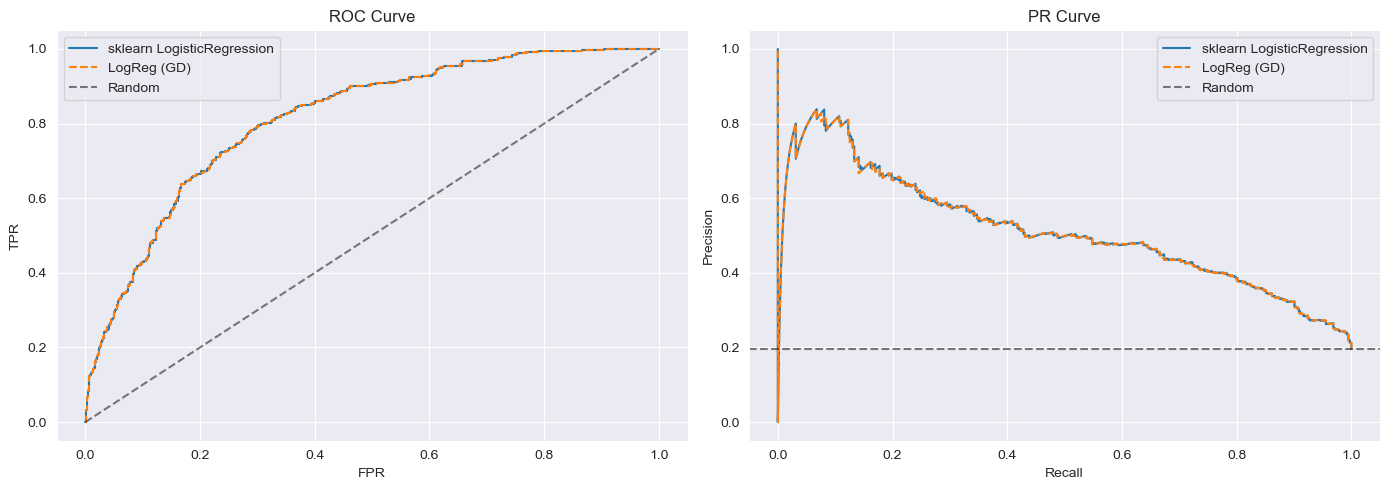

,ROC-AUC,PR-AUC
sklearn LogisticRegression,0.813537,0.512115
LogReg (GD),0.813487,0.512042


p                 : ROC-AUC = 0.813537
10 * p            : ROC-AUC = 0.813537
p^3               : ROC-AUC = 0.813537
log(p / (1 - p))  : ROC-AUC = 0.813537
-p                : ROC-AUC = 0.186463
predicted labels  : ROC-AUC = 0.606878


In [14]:
pipe_custom = make_pipeline(StandardScaler(), LogReg(gd_type='full', eta=0.5, max_iter=5000))
pipe_custom.fit(X_train, y_train)

prob_sk = pipe_lr.predict_proba(X_test)[:, 1]
prob_custom = pipe_custom.predict_proba(X_test)[:, 1]

fpr_sk, tpr_sk, _ = metrics.roc_curve(y_test, prob_sk)
fpr_custom, tpr_custom, _ = metrics.roc_curve(y_test, prob_custom)

prec_sk, rec_sk, _ = metrics.precision_recall_curve(y_test, prob_sk)
prec_custom, rec_custom, _ = metrics.precision_recall_curve(y_test, prob_custom)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr_sk, tpr_sk, label='sklearn LogisticRegression')
axes[0].plot(fpr_custom, tpr_custom, linestyle='--', label='LogReg (GD)')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
axes[0].set_xlabel('FPR')
axes[0].set_ylabel('TPR')
axes[0].set_title('ROC Curve')
axes[0].legend()

axes[1].plot(rec_sk, prec_sk, label='sklearn LogisticRegression')
axes[1].plot(rec_custom, prec_custom, linestyle='--', label='LogReg (GD)')
axes[1].axhline(y_test.mean(), color='k', linestyle='--', alpha=0.5, label='Random')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('PR Curve')
axes[1].legend()

plt.tight_layout()
plt.show()

auc_df = pd.DataFrame({
    'ROC-AUC': [
        metrics.roc_auc_score(y_test, prob_sk),
        metrics.roc_auc_score(y_test, prob_custom)
    ],
    'PR-AUC': [
        metrics.average_precision_score(y_test, prob_sk),
        metrics.average_precision_score(y_test, prob_custom)
    ]
}, index=['sklearn LogisticRegression', 'LogReg (GD)'])
display(auc_df)

p = prob_sk
transformed_scores = {
    'p': p,
    '10 * p': 10 * p,
    'p^3': p ** 3,
    'log(p / (1 - p))': np.log(p / (1 - p)),
    '-p': -p,
    'predicted labels': pipe_lr.predict(X_test)
}

for name, score in transformed_scores.items():
    print(f'{name:18s}: ROC-AUC = {metrics.roc_auc_score(y_test, score):.6f}')

На этой тестовой выборке sklearn немного лучше по обеим метрикам: ROC-AUC ≈ 0.813537 и PR-AUC ≈ 0.512115 против 0.813487 и 0.512042 у своей модели. Ранжирование моделей совпало, но различия очень малы. Собственный GD остановился по `tolerance` за 2554 итерации.

Уровень случайного ранжирования на PR-графике соответствует доле положительного класса, здесь около 0.1964. Он не равен 0.5, поскольку классы несбалансированы. Для конечной случайной перестановки фактический average precision может отклоняться от этого базового уровня.

Преобразования `10*p`, `p**3` и `log(p/(1-p))` строго возрастают на используемом диапазоне вероятностей и сохраняют порядок объектов, поэтому ROC-AUC не меняется. Преобразование `-p` обращает порядок: ROC-AUC становится примерно 0.186463, то есть `1 - исходный ROC-AUC`.

При передаче меток классов ROC-AUC вычислить можно, здесь он равен примерно 0.606878. Но две возможные оценки 0 и 1 теряют информацию о ранжировании внутри классов предсказаний; получается площадь под ROC с одной промежуточной рабочей точкой, равная среднему TPR и TNR.


### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

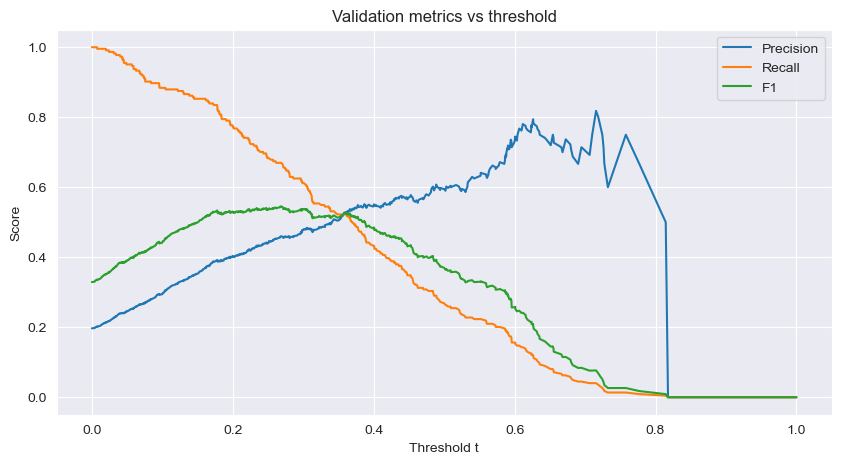

t_F1 = 0.268889, t_R = 0.243196


,Precision,Recall,F1
Threshold,,,
0.5 (0.50),0.597561,0.255875,0.358318
t_F1 (0.27),0.473888,0.639687,0.544444
t_R (0.24),0.436975,0.678851,0.531697


In [15]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE
)

pipe_val = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
pipe_val.fit(X_tr, y_tr)
val_probs = pipe_val.predict_proba(X_val)[:, 1]

thresholds = np.unique(np.concatenate(([0.0], val_probs, [1.0])))
val_prec, val_rec, val_f1 = [], [], []

for t in thresholds:
    preds = (val_probs >= t).astype(int)
    val_prec.append(metrics.precision_score(y_val, preds, zero_division=0))
    val_rec.append(metrics.recall_score(y_val, preds, zero_division=0))
    val_f1.append(metrics.f1_score(y_val, preds, zero_division=0))

val_prec = np.array(val_prec)
val_rec = np.array(val_rec)
val_f1 = np.array(val_f1)

plt.figure(figsize=(10, 5))
plt.plot(thresholds, val_prec, label='Precision')
plt.plot(thresholds, val_rec, label='Recall')
plt.plot(thresholds, val_f1, label='F1')
plt.xlabel('Threshold t')
plt.ylabel('Score')
plt.title('Validation metrics vs threshold')
plt.legend()
plt.show()

t_f1 = thresholds[np.argmax(val_f1)]
mask_r = val_rec >= 0.7
t_r = thresholds[mask_r][np.argmax(val_prec[mask_r])]

print(f't_F1 = {t_f1:.6f}, t_R = {t_r:.6f}')

pipe_lr.fit(X_train, y_train)
test_probs = pipe_lr.predict_proba(X_test)[:, 1]

thresh_rows = []
for name, t in [('0.5', 0.5), ('t_F1', t_f1), ('t_R', t_r)]:
    preds = (test_probs >= t).astype(int)
    thresh_rows.append({
        'Threshold': f'{name} ({t:.2f})',
        'Precision': metrics.precision_score(y_test, preds, zero_division=0),
        'Recall': metrics.recall_score(y_test, preds, zero_division=0),
        'F1': metrics.f1_score(y_test, preds, zero_division=0)
    })

df_thresholds = pd.DataFrame(thresh_rows).set_index('Threshold')
display(df_thresholds)

Пороги выбраны только по валидации: t_F1 ≈ 0.268889 максимизирует F1, t_R ≈ 0.243196 максимизирует precision среди вариантов с recall ≥ 0.7. Перебираются уникальные валидационные вероятности и границы 0 и 1, поэтому учитываются все возможные изменения предсказаний.

На валидации у t_R recall ≈ 0.7009. После переобучения на всём train на тесте он составляет около 0.6789, поэтому условие recall ≥ 0.7 не выполнено. Это возможно из-за различий выборок и изменения модели при переобучении: ограничение на валидации не гарантирует того же результата на новых данных.

Для исходного сценария с компромиссом между точностью и полнотой выберу t_F1: на тесте precision ≈ 0.4739, recall ≈ 0.6397 и F1 ≈ 0.5444. При пороге 0.5 precision выше, около 0.5976, но recall существенно ниже, около 0.2559. Порог t_R даёт больший охват, чем t_F1, ценой меньшей точности рекомендаций.


## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
def evaluate_model(model, X_te, y_te, threshold=0.5):
    probs = model.predict_proba(X_te)[:, 1]
    preds = (probs >= threshold).astype(int)
    return {
        'Accuracy': metrics.accuracy_score(y_te, preds),
        'Precision': metrics.precision_score(y_te, preds, zero_division=0),
        'Recall': metrics.recall_score(y_te, preds, zero_division=0),
        'F1': metrics.f1_score(y_te, preds, zero_division=0),
        'ROC-AUC': metrics.roc_auc_score(y_te, probs),
        'PR-AUC': metrics.average_precision_score(y_te, probs)
    }

w0_bal = len(y_train) / (2 * np.sum(y_train == 0))
w1_bal = len(y_train) / (2 * np.sum(y_train == 1))
print(f'Class 0 weight: {w0_bal:.4f}, Class 1 weight: {w1_bal:.4f}')

pipe_none = make_pipeline(StandardScaler(), LogisticRegression(class_weight=None, random_state=RANDOM_STATE))
pipe_bal = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE))

pipe_none.fit(X_train, y_train)
pipe_bal.fit(X_train, y_train)

metrics_part3 = pd.DataFrame({
    'LogReg (class_weight=None)': evaluate_model(pipe_none, X_test, y_test),
    'LogReg (class_weight=balanced)': evaluate_model(pipe_bal, X_test, y_test)
}).T

display(metrics_part3)

Class 0 weight: 0.6224, Class 1 weight: 2.5431


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
LogReg (class_weight=None),0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
LogReg (class_weight=balanced),0.726667,0.396978,0.754569,0.520252,0.811339,0.500536


Веса вычислены по формуле `n_samples / (n_classes * n_samples_in_class)`: класс 0 получает около 0.6224, класс 1 — 2.5431. Ошибки на редком положительном классе становятся существенно дороже.

При `class_weight='balanced'` recall растёт примерно с 0.2559 до 0.7546, а precision падает с 0.5976 до 0.3970. F1 увеличивается с 0.3583 до 0.5203, accuracy уменьшается с 0.8200 до 0.7267. Модель чаще рекомендует вино как хорошее, поэтому находит больше хороших образцов, но допускает больше ложных рекомендаций.

ROC-AUC меняется мало: примерно с 0.8135 до 0.8113; PR-AUC — с 0.5121 до 0.5005. Эти метрики оценивают ранжирование при разных порогах, которое изменилось меньше, чем решение при фиксированном пороге 0.5.


### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {
    'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
    'NearMiss(version=2)': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
    'SMOTE': SMOTE(random_state=RANDOM_STATE)
}

resampling_models = {}
X_train_scaled = StandardScaler().fit_transform(X_train)

for name, sampler in samplers.items():
    X_res, y_res = sampler.fit_resample(X_train_scaled, y_train)
    print(f'{name}: class 0 = {np.sum(y_res == 0)}, class 1 = {np.sum(y_res == 1)}')
    pipe = make_imb_pipeline(StandardScaler(), sampler, LogisticRegression(random_state=RANDOM_STATE))
    pipe.fit(X_train, y_train)
    resampling_models[name] = pipe
    metrics_part3.loc[name] = evaluate_model(pipe, X_test, y_test)

display(metrics_part3)

pipe_smote_unscaled_first = make_imb_pipeline(
    SMOTE(random_state=RANDOM_STATE),
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)
).fit(X_train, y_train)

order_df = pd.DataFrame({
    'StandardScaler -> SMOTE': metrics_part3.loc['SMOTE'],
    'SMOTE -> StandardScaler': evaluate_model(pipe_smote_unscaled_first, X_test, y_test)
}).T
display(order_df)

RandomUnderSampler: class 0 = 894, class 1 = 894
NearMiss(version=2): class 0 = 894, class 1 = 894
RandomOverSampler: class 0 = 3653, class 1 = 3653
SMOTE: class 0 = 3653, class 1 = 3653


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
LogReg (class_weight=None),0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
LogReg (class_weight=balanced),0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
RandomUnderSampler,0.729744,0.401099,0.762402,0.525653,0.809354,0.500791
NearMiss(version=2),0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
RandomOverSampler,0.726667,0.397260,0.757180,0.521114,0.811484,0.500225
SMOTE,0.729231,0.399166,0.749347,0.520871,0.812465,0.503985


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
StandardScaler -> SMOTE,0.729231,0.399166,0.749347,0.520871,0.812465,0.503985
SMOTE -> StandardScaler,0.733846,0.404225,0.749347,0.525160,0.811607,0.508955


После RandomUnderSampler и NearMiss в train остаётся по 894 объекта каждого класса. После RandomOverSampler и SMOTE получается по 3653 объекта каждого класса.

Здесь нужен пайплайн imblearn, поскольку ресемплеры меняют одновременно X и y через `fit_resample`, а обычный пайплайн sklearn ожидает преобразования признаков через `transform`. При `predict` и `predict_proba` ресемплинг пропускается: тестовые объекты только масштабируются и передаются модели.

Балансировать весь датасет до разбиения нельзя: это изменяет распределение классов на тесте и может передавать информацию между train и test через копии объектов, соседей или синтетические образцы.

Среди четырёх основных пайплайнов лучший PR-AUC у SMOTE, около 0.5040, худший — у NearMiss(version=2), около 0.4001. SMOTE сохраняет большинство исходных данных и добавляет объекты редкого класса. NearMiss удаляет значительную часть класса 0 по расстояниям, что в этом эксперименте ухудшает его представленность и качество ранжирования. При этом базовая модель без балансировки имеет более высокий PR-AUC, около 0.5121: балансировка не гарантирует улучшения.

Масштабирование перед NearMiss и SMOTE важно для поиска соседей: без него признаки с большими численными диапазонами сильнее влияют на расстояния. Для RandomUnderSampler и RandomOverSampler выбранные индексы от масштаба не зависят. Однако перенос обучения StandardScaler после ресемплинга меняет его статистики и может менять итоговую регуляризованную модель даже для случайных методов.

В проверке порядка шагов PR-AUC составляет около 0.5040 для `StandardScaler -> SMOTE` и 0.5090 для `SMOTE -> StandardScaler`. В данном разбиении второй порядок оказался немного лучше по этой метрике; это результат конкретного эксперимента, а не общее преимущество вычисления соседей без масштабирования.


### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

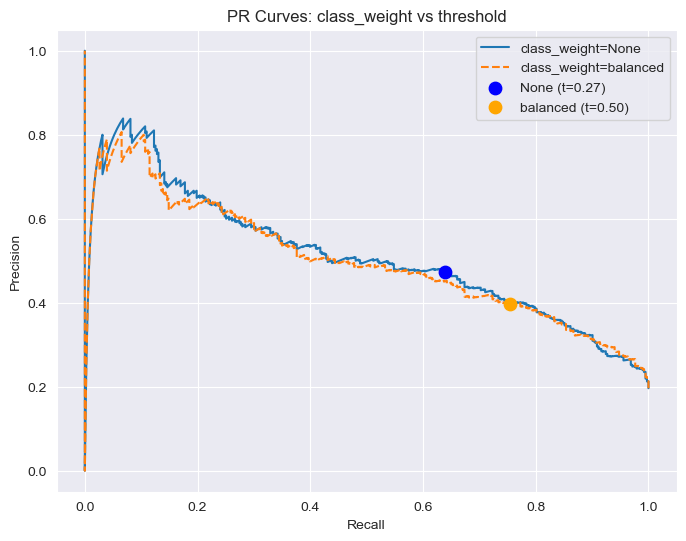

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
class_weight=None (t=0.27),0.789744,0.473888,0.639687,0.544444,0.813537,0.512115
class_weight=balanced (t=0.50),0.726667,0.396978,0.754569,0.520252,0.811339,0.500536


In [18]:
prob_none = pipe_none.predict_proba(X_test)[:, 1]
prob_bal = pipe_bal.predict_proba(X_test)[:, 1]

prec_none, rec_none, _ = metrics.precision_recall_curve(y_test, prob_none)
prec_bal, rec_bal, _ = metrics.precision_recall_curve(y_test, prob_bal)

pred_none_tf1 = (prob_none >= t_f1).astype(int)
pt_prec_none = metrics.precision_score(y_test, pred_none_tf1)
pt_rec_none = metrics.recall_score(y_test, pred_none_tf1)

pred_bal_05 = (prob_bal >= 0.5).astype(int)
pt_prec_bal = metrics.precision_score(y_test, pred_bal_05)
pt_rec_bal = metrics.recall_score(y_test, pred_bal_05)

plt.figure(figsize=(8, 6))
plt.plot(rec_none, prec_none, label='class_weight=None')
plt.plot(rec_bal, prec_bal, linestyle='--', label='class_weight=balanced')
plt.scatter([pt_rec_none], [pt_prec_none], color='blue', s=80, zorder=5, label=f'None (t={t_f1:.2f})')
plt.scatter([pt_rec_bal], [pt_prec_bal], color='orange', s=80, zorder=5, label='balanced (t=0.50)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR Curves: class_weight vs threshold')
plt.legend()
plt.show()

comp_3_3 = pd.DataFrame({
    f'class_weight=None (t={t_f1:.2f})': evaluate_model(pipe_none, X_test, y_test, threshold=t_f1),
    'class_weight=balanced (t=0.50)': evaluate_model(pipe_bal, X_test, y_test, threshold=0.5)
}).T
display(comp_3_3)

При пороге t_F1 ≈ 0.268889 модель без весов получает precision ≈ 0.4739, recall ≈ 0.6397 и F1 ≈ 0.5444. Взвешенная модель при пороге 0.5 получает precision ≈ 0.3970, recall ≈ 0.7546 и F1 ≈ 0.5203.

PR-кривые близки, но не совпадают: PR-AUC составляет около 0.5121 без весов и 0.5005 с весами. Обе настройки позволяют увеличить полноту по сравнению с обычным порогом 0.5, но дают разные рабочие точки.

Взвешивание классов во многом похоже на сдвиг порога, поскольку меняет предпочтение модели в пользу редкого класса. Однако это не точная эквивалентность: при обучении меняются коэффициенты и может измениться ранжирование объектов. Изменение порога уже обученной модели ранжирование и её PR-кривую не меняет.


### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
summary_rows = {
    'Constant (class 0)': {
        'Accuracy': metrics.accuracy_score(y_test, const_pred),
        'Precision': 0.0,
        'Recall': 0.0,
        'F1': 0.0,
        'ROC-AUC': 0.5,
        'PR-AUC': y_test.mean()
    },
    'LogReg (GD, custom)': evaluate_model(pipe_custom, X_test, y_test, threshold=0.5),
    'LogReg (t=0.50)': evaluate_model(pipe_none, X_test, y_test, threshold=0.5),
    f'LogReg (t_F1={t_f1:.2f})': evaluate_model(pipe_none, X_test, y_test, threshold=t_f1),
    f'LogReg (t_R={t_r:.2f})': evaluate_model(pipe_none, X_test, y_test, threshold=t_r),
    'LogReg (class_weight=balanced)': evaluate_model(pipe_bal, X_test, y_test, threshold=0.5),
    'RandomUnderSampler': evaluate_model(resampling_models['RandomUnderSampler'], X_test, y_test, threshold=0.5),
    'NearMiss(version=2)': evaluate_model(resampling_models['NearMiss(version=2)'], X_test, y_test, threshold=0.5),
    'RandomOverSampler': evaluate_model(resampling_models['RandomOverSampler'], X_test, y_test, threshold=0.5),
    'SMOTE': evaluate_model(resampling_models['SMOTE'], X_test, y_test, threshold=0.5)
}

df_summary = pd.DataFrame(summary_rows).T
display(df_summary.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Constant (class 0),0.8036,0.0000,0.0000,0.0000,0.5000,0.1964
"LogReg (GD, custom)",0.8210,0.6024,0.2611,0.3643,0.8135,0.5120
LogReg (t=0.50),0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
LogReg (t_F1=0.27),0.7897,0.4739,0.6397,0.5444,0.8135,0.5121
LogReg (t_R=0.24),0.7651,0.4370,0.6789,0.5317,0.8135,0.5121
LogReg (class_weight=balanced),0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
RandomUnderSampler,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
NearMiss(version=2),0.5441,0.2819,0.8538,0.4238,0.7399,0.4001
RandomOverSampler,0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
SMOTE,0.7292,0.3992,0.7493,0.5209,0.8125,0.5040


Для исходного сценария предлагаю `StandardScaler + LogisticRegression` без весов классов с порогом t_F1 ≈ 0.268889. Среди основных рассмотренных вариантов он даёт наибольший тестовый F1, около 0.5444, при precision ≈ 0.4739 и recall ≈ 0.6397. Порог выбран по валидации. По сравнению с порогом 0.5 он позволяет включить значительно больше хороших вин, сохраняя более высокий precision, чем у рассмотренных методов балансировки.

Базовая модель также имеет наибольший PR-AUC в итоговой таблице, около 0.5121. Константная модель с accuracy около 0.8036 непригодна для рекомендаций, поскольку не находит ни одного хорошего вина.

Такой выбор является компромиссом: примерно половина рекомендаций при этом пороге ошибочна. Если сервису критически важна точность подборки, потребуется выбирать порог по соответствующему критерию на валидации. Условие recall ≥ 0.7 у t_R на тесте не выполнено, поэтому обещать такой охват по текущему результату нельзя.


### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = pipe_none
final_threshold = t_f1

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)

## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

Репозиторий GitHub: [тык сюда](https://github.com/amirkasheesh/hw3-mmda)

Приложение Streamlit: [тык сюда](https://hw3-mmda-deln4gcu2ajwb2gebdhkqw.streamlit.app)